<a href="https://colab.research.google.com/github/Minhhieu3012/wifi-localization-data-mining/blob/main/Main_WiFi_Localization_Group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📡 BÀI TẬP DỰ ÁN: PHÂN TÍCH & KHAI THÁC DỮ LIỆU ĐỊNH VỊ TRONG NHÀ BẰNG TÍN HIỆU WIFI (D08 - WIFI LOCALIZATION)

* **Bộ dữ liệu:** `D08 - wifi_localization.xlsx` (Sheet: `wifi_localization`) — xuất ra file chuẩn `wifi_localization.csv` (`2.000 mẫu × 8 cột`).
* **Bài toán thực tế:** Xác định vị trí người dùng trong nhà (1 trong 4 căn phòng: `Room 1, 2, 3, 4`) dựa trên cường độ tín hiệu thu được (`RSSI`, đơn vị `dBm`) từ 7 trạm phát sóng WiFi (`WiFi_1` đến `WiFi_7`).
* **Cấu trúc nội dung thực hiện theo đúng yêu cầu đề bài:**
  * **Lưu ý mở đầu:** Xuất bảng dữ liệu từ file Excel gốc ra định dạng file `CSV` trước khi đọc vào bộ nhớ.
  * **Bước 1 — Đọc dữ liệu và Khám phá (EDA):** Kích thước & số chiều `(a)`, kiểu dữ liệu các thuộc tính `(b)`, số lượng thực thể của từng nhãn & biểu đồ phân bố `(c)`, thống kê `Min`, `Max`, `Mean` của các thuộc tính số thực `(d)`, kiểm tra dữ liệu thiếu/trùng lặp `(e)` và phân tích ngoại lai bằng Boxplot `(f)`.
  * **Bước 2 — Tạo Data mới và Trực quan hóa (PCA 2D):** Chỉ lấy 7 cột thuộc tính liên tục, chuẩn hóa `StandardScaler`, giảm chiều bằng `PCA` xuống không gian 2D (`PC1`, `PC2`) và vẽ biểu đồ phân tán với màu sắc riêng cho từng lớp nhãn.
  * **Bước 3 — Huấn luyện mô hình phân lớp (`k = 10` Fold Cross-Validation):** Tinh chỉnh siêu tham số (`GridSearchCV`) cho 3 mô hình **KNN**, **Random Forest**, **SVM (RBF)** và lập bảng so sánh hiệu năng với độ đo **F-Score (`k = 10`)**.
  * **Bước 4 — Gom cụm dữ liệu (`K-Means` & `DBSCAN`):** Loại trừ cột nhãn `Room`, thực hiện gom cụm với `K-Means` và `DBSCAN`, trực quan hóa trên không gian `PCA 2D` (hiển thị rõ các cụm và điểm **Nhiễu**) và lập bảng đánh giá kết quả gom cụm bằng độ đo **Adjusted Rand Index (ARI)**.

---
## 0. LƯU Ý MỞ ĐẦU: XUẤT BẢNG DỮ LIỆU RA FILE CSV TRƯỚC KHI ĐỌC

* **Mục tiêu:** Đọc dữ liệu từ file Excel gốc `D08 - wifi_localization.xlsx` (sheet `wifi_localization`) với tham số `header=None` để không bị mất mẫu dữ liệu đầu tiên của Phòng 1, đặt tên chuẩn cho 7 cột thuộc tính tín hiệu (`WiFi_1` .. `WiFi_7`) và cột nhãn (`Room`), sau đó **xuất ra file `wifi_localization.csv`** và đọc lại từ file CSV để phục vụ toàn bộ các bước phân tích tiếp theo.

In [2]:
# ==============================================================================
# PHẦN 0: KHỞI TẠO MÔI TRƯỜNG & XUẤT BẢNG DỮ LIỆU RA FILE CSV TRƯỚC KHI ĐỌC
# ==============================================================================
from pathlib import Path
from urllib.parse import unquote
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cố định hạt giống ngẫu nhiên dùng chung cho toàn bộ dự án
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Cấu hình hiển thị chung cho bảng biểu và đồ thị
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11
pd.set_option("display.precision", 4)

FEATURES = [f"WiFi_{i}" for i in range(1, 8)]
TARGET = "Room"
COLUMNS = FEATURES + [TARGET]


def find_project_root() -> Path:
    """Tìm thư mục gốc của dự án khi chạy trên máy cục bộ hoặc Google Colab."""
    current = Path.cwd()
    for folder in (current, *current.parents):
        if (folder / "data" / "raw" / "D08 - wifi_localization.xlsx").is_file():
            return folder
    return current


ROOT = find_project_root()
EXCEL_PATH = ROOT / "data" / "raw" / "D08 - wifi_localization.xlsx"
CSV_PATH = ROOT / "data" / "processed" / "wifi_localization.csv"
GITHUB_EXCEL_URL = (
    "https://raw.githubusercontent.com/Minhhieu3012/"
    "wifi-localization-data-mining/main/data/raw/D08%20-%20wifi_localization.xlsx"
)

# 1. Đọc file Excel gốc (ưu tiên file trong dự án, nếu chạy trên Colab thì tải từ GitHub)
excel_source = EXCEL_PATH if EXCEL_PATH.is_file() else GITHUB_EXCEL_URL
print("=== 1. ĐỌC FILE EXCEL GỐC ===")
print("Nguồn dữ liệu:", excel_source if isinstance(excel_source, Path) else unquote(excel_source.split("/")[-1]))

excel_file = pd.ExcelFile(excel_source)
print("Danh sách sheet trong file Excel:", excel_file.sheet_names)

df_raw = pd.read_excel(excel_source, sheet_name="wifi_localization", header=None)
assert df_raw.shape == (2000, 8), f"Kích thước dữ liệu gốc không khớp: {df_raw.shape}"

# 2. Đặt tên cột, chuẩn hóa kiểu dữ liệu và xuất ra file CSV
df_export = df_raw.copy()
df_export.columns = COLUMNS
for col in FEATURES:
    df_export[col] = pd.to_numeric(df_export[col], errors="raise").astype("float64")
df_export[TARGET] = pd.to_numeric(df_export[TARGET], errors="raise").astype("int64")

CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
df_export.to_csv(CSV_PATH, index=False, encoding="utf-8")
# Lưu thêm một bản tại thư mục làm việc hiện tại để tương thích thuận tiện trên Google Colab
df_export.to_csv("wifi_localization.csv", index=False, encoding="utf-8")

# 3. Đọc lại dữ liệu từ file CSV vừa xuất và đối chiếu tính toàn vẹn
df = pd.read_csv(CSV_PATH)
pd.testing.assert_frame_equal(df_export, df)

print("\n=== 2. XUẤT VÀ ĐỌC LẠI FILE CSV THÀNH CÔNG ===")
print("Đường dẫn file CSV:", CSV_PATH)
print("Kích thước bảng CSV:", df.shape)
print("Tổng số giá trị thiếu:", int(df.isna().sum().sum()))
display(df.head())

=== 1. ĐỌC FILE EXCEL GỐC ===
Nguồn dữ liệu: D08 - wifi_localization.xlsx
Danh sách sheet trong file Excel: ['Sheet1', 'wifi_localization']

=== 2. XUẤT VÀ ĐỌC LẠI FILE CSV THÀNH CÔNG ===
Đường dẫn file CSV: /content/data/processed/wifi_localization.csv
Kích thước bảng CSV: (2000, 8)
Tổng số giá trị thiếu: 0


,WiFi_1,WiFi_2,WiFi_3,WiFi_4,WiFi_5,WiFi_6,WiFi_7,Room
0,-64.0,-56.0,-61.0,-66.0,-71.0,-82.0,-81.0,1
1,-68.0,-57.0,-61.0,-65.0,-71.0,-85.0,-85.0,1
2,-63.0,-60.0,-60.0,-67.0,-76.0,-85.0,-84.0,1
3,-61.0,-60.0,-68.0,-62.0,-77.0,-90.0,-80.0,1
4,-63.0,-65.0,-60.0,-63.0,-77.0,-81.0,-87.0,1


**Nhận xét Phần 0:**
* File Excel gốc `D08 - wifi_localization.xlsx` gồm 2 sheet (`Sheet1` và `wifi_localization`), trong đó dữ liệu thực tế nằm ở sheet `wifi_localization` và **không có dòng tiêu đề (`header=None`)**. Việc đọc với `header=None` giúp bảo toàn trọn vẹn mẫu đầu tiên `[-64, -56, -61, -66, -71, -82, -81, 1]` của Phòng 1 (đảm bảo đủ `2.000 mẫu`).
* Dữ liệu sau khi gán nhãn cột `WiFi_1` .. `WiFi_7` và `Room` đã được xuất ra file `wifi_localization.csv` và kiểm tra đối chiếu khớp 100% trước khi bước vào Bước 1.

---
## 1. BƯỚC 1: ĐỌC DỮ LIỆU VÀ KHÁM PHÁ (EDA)

### 1a. Kích thước và số chiều của dữ liệu `(n, m)`
* **Mục tiêu:** Đọc dữ liệu từ file `wifi_localization.csv` vào bộ nhớ và xác định số lượng mẫu quan sát (`n`), tổng số thuộc tính (`m`), số chiều đặc trưng đầu vào và số lớp nhãn đầu ra.

In [3]:
# ==============================================================================
# BƯỚC 1A: KÍCH THƯỚC VÀ CHIỀU CỦA DỮ LIỆU (n, m)
# ==============================================================================
df = pd.read_csv(CSV_PATH)

so_mau, so_cot = df.shape
so_dac_trung = len(FEATURES)
so_lop = df[TARGET].nunique()

info_size_df = pd.DataFrame({
    "Thông số dữ liệu": [
        "Kích thước bảng dữ liệu (n, m)",
        "Số lượng mẫu quan sát (n)",
        "Tổng số cột thuộc tính (m)",
        "Số chiều đặc trưng đầu vào (WiFi_1 -> WiFi_7)",
        "Số lượng lớp nhãn đầu ra (Room 1 -> 4)",
    ],
    "Giá trị": [
        f"({so_mau}, {so_cot})",
        so_mau,
        so_cot,
        so_dac_trung,
        so_lop,
    ],
})

print("=== 1A. THÔNG TIN KÍCH THƯỚC VÀ CHIỀU DỮ LIỆU ===")
display(info_size_df)

print("\n=== 5 DÒNG DỮ LIỆU ĐẦU TIÊN ===")
display(df.head())

assert df.shape == (2000, 8)
assert so_lop == 4

=== 1A. THÔNG TIN KÍCH THƯỚC VÀ CHIỀU DỮ LIỆU ===


,Thông số dữ liệu,Giá trị
0,"Kích thước bảng dữ liệu (n, m)","(2000, 8)"
1,Số lượng mẫu quan sát (n),2000
2,Tổng số cột thuộc tính (m),8
3,Số chiều đặc trưng đầu vào (WiFi_1 -> WiFi_7),7
4,Số lượng lớp nhãn đầu ra (Room 1 -> 4),4



=== 5 DÒNG DỮ LIỆU ĐẦU TIÊN ===


,WiFi_1,WiFi_2,WiFi_3,WiFi_4,WiFi_5,WiFi_6,WiFi_7,Room
0,-64.0,-56.0,-61.0,-66.0,-71.0,-82.0,-81.0,1
1,-68.0,-57.0,-61.0,-65.0,-71.0,-85.0,-85.0,1
2,-63.0,-60.0,-60.0,-67.0,-76.0,-85.0,-84.0,1
3,-61.0,-60.0,-68.0,-62.0,-77.0,-90.0,-80.0,1
4,-63.0,-65.0,-60.0,-63.0,-77.0,-81.0,-87.0,1


**Nhận xét 1a:** Bộ dữ liệu WiFi Localization có kích thước `(n, m) = (2000, 8)` tương ứng với `2.000 mẫu quan sát` và `8 thuộc tính`. Trong đó, `7 thuộc tính đầu vào` (`WiFi_1` đến `WiFi_7`) biểu diễn cường độ tín hiệu WiFi thu được từ 7 trạm phát sóng (Access Points), còn thuộc tính `Room` thể hiện nhãn vị trí tương ứng với `4 căn phòng`.

---
### 1b. Kiểu dữ liệu của các thuộc tính (`int, float, object, ...`)
* **Mục tiêu:** Kiểm tra kiểu dữ liệu của từng cột thuộc tính, chuẩn hóa 7 đặc trưng tín hiệu WiFi sang số thực `float64` để phản ánh đúng bản chất đại lượng đo lường liên tục (`RSSI` tính theo `dBm`) và giữ cột nhãn `Room` ở kiểu số nguyên `int64`.

In [4]:
# ==============================================================================
# BƯỚC 1B: KIỂM TRA KIỂU DỮ LIỆU CỦA CÁC THUỘC TÍNH
# ==============================================================================
df[FEATURES] = df[FEATURES].astype("float64")
df[TARGET] = df[TARGET].astype("int64")

dtype_summary_df = pd.DataFrame({
    "Tên thuộc tính": df.columns,
    "Kiểu dữ liệu (dtype)": [str(dt) for dt in df.dtypes],
    "Số giá trị khác Null": df.notna().sum().values,
    "Vai trò & Bản chất thuộc tính": [
        *(["Đặc trưng đầu vào — Cường độ tín hiệu RSSI liên tục (dBm, số thực)"] * 7),
        "Nhãn phân lớp (Target) — Mã phòng định danh (1, 2, 3, 4)",
    ],
})

print("=== 1B. BẢNG KIỂU DỮ LIỆU CỦA CÁC THUỘC TÍNH ===")
display(dtype_summary_df)

print("\n=== THÔNG TIN CHI TIẾT DATAFRAME (df.info) ===")
df.info()

assert all(df[col].dtype == "float64" for col in FEATURES)
assert df[TARGET].dtype == "int64"

=== 1B. BẢNG KIỂU DỮ LIỆU CỦA CÁC THUỘC TÍNH ===


,Tên thuộc tính,Kiểu dữ liệu (dtype),Số giá trị khác Null,Vai trò & Bản chất thuộc tính
0,WiFi_1,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
1,WiFi_2,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
2,WiFi_3,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
3,WiFi_4,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
4,WiFi_5,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
5,WiFi_6,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
6,WiFi_7,float64,2000,Đặc trưng đầu vào — Cường độ tín hiệu RSSI liê...
7,Room,int64,2000,Nhãn phân lớp (Target) — Mã phòng định danh (1...



=== THÔNG TIN CHI TIẾT DATAFRAME (df.info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   WiFi_1  2000 non-null   float64
 1   WiFi_2  2000 non-null   float64
 2   WiFi_3  2000 non-null   float64
 3   WiFi_4  2000 non-null   float64
 4   WiFi_5  2000 non-null   float64
 5   WiFi_6  2000 non-null   float64
 6   WiFi_7  2000 non-null   float64
 7   Room    2000 non-null   int64  
dtypes: float64(7), int64(1)
memory usage: 125.1 KB


**Nhận xét 1b:** Bảy thuộc tính `WiFi_1` đến `WiFi_7` biểu diễn cường độ tín hiệu nhận được (`RSSI`), đo bằng đơn vị `dBm`. Mặc dù thiết bị thu ghi nhận giá trị làm tròn, về bản chất vật lý `RSSI` là **đại lượng liên tục (giá trị số thực)** nên được chuẩn hóa sang `float64` để phục vụ thống kê mô tả, chuẩn hóa `StandardScaler` và giảm chiều `PCA`. Cột `Room` mang ý nghĩa nhãn danh mục của 4 phòng nên giữ kiểu `int64`.

---
### 1c. Số lượng thực thể của các giá trị nhãn (Phân bố nhãn)
* **Mục tiêu:** Thống kê số lượng mẫu và tỷ lệ phần trăm của từng nhãn phòng (`Room 1, 2, 3, 4`), đồng thời trực quan hóa bằng biểu đồ cột để kiểm tra tính cân bằng của bộ dữ liệu.

=== 1C. BẢNG PHÂN BỐ SỐ LƯỢNG THỰC THỂ THEO NHÃN PHÒNG ===


,Nhãn Phòng (Room),Số lượng thực thể (Mẫu),Tỷ lệ (%)
0,Phòng 1,500,25.0
1,Phòng 2,500,25.0
2,Phòng 3,500,25.0
3,Phòng 4,500,25.0


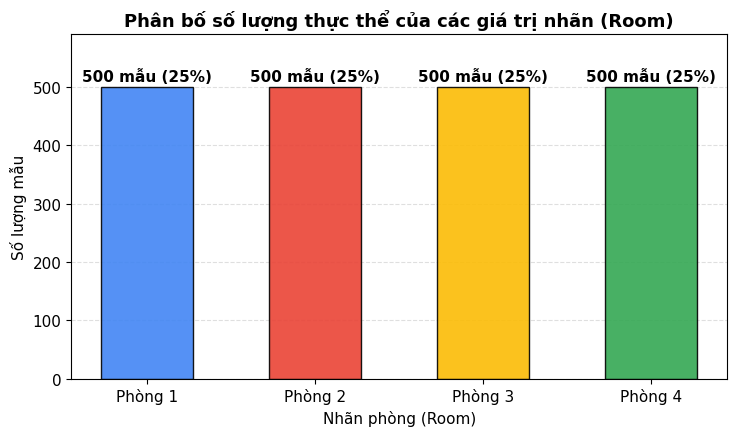

In [5]:
# ==============================================================================
# BƯỚC 1C: SỐ LƯỢNG THỰC THỂ CỦA CÁC GIÁ TRỊ NHÃN & BIỂU ĐỒ PHÂN BỐ
# ==============================================================================
room_counts = df[TARGET].value_counts().sort_index()
room_percent = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)

room_distribution = pd.DataFrame({
    "Nhãn Phòng (Room)": [f"Phòng {r}" for r in room_counts.index],
    "Số lượng thực thể (Mẫu)": room_counts.values,
    "Tỷ lệ (%)": room_percent.values,
})

print("=== 1C. BẢNG PHÂN BỐ SỐ LƯỢNG THỰC THỂ THEO NHÃN PHÒNG ===")
display(room_distribution)

# Vẽ biểu đồ cột phân bố nhãn như minh họa trên đề bài
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(
    [f"Phòng {r}" for r in room_counts.index],
    room_counts.values,
    color=["#4285F4", "#EA4335", "#FBBC05", "#34A853"],
    width=0.55,
    edgecolor="black",
    alpha=0.9,
)

ax.set_title("Phân bố số lượng thực thể của các giá trị nhãn (Room)", fontsize=13, fontweight="bold")
ax.set_xlabel("Nhãn phòng (Room)")
ax.set_ylabel("Số lượng mẫu")
ax.set_ylim(0, room_counts.max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    height = int(bar.get_height())
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 10,
        f"{height} mẫu (25%)",
        ha="center",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

assert room_counts.sum() == 2000 and room_counts.nunique() == 1

**Nhận xét 1c:** Bộ dữ liệu gồm đúng `4 lớp nhãn` tương ứng với 4 căn phòng, mỗi phòng có chính xác **500 mẫu quan sát (chiếm 25,0%)**. Phân bố nhãn cân bằng tuyệt đối giúp quá trình huấn luyện mô hình phân lớp với `10-Fold Stratified Cross-Validation` và đánh giá bằng độ đo `F1-Score` không bị chệch (bias) về bất kỳ lớp nào.

---
### 1d. Giá trị lớn nhất (`Max`), bé nhất (`Min`), và trung bình (`Mean`) của các cột thuộc tính có giá trị số thực
* **Mục tiêu:** Lập bảng thống kê mô tả gồm 3 chỉ số `Min`, `Max`, `Mean` (kèm độ lệch chuẩn `Std` và biên độ `Range`) cho 7 cột thuộc tính số thực `WiFi_1` .. `WiFi_7` theo đúng mẫu bảng trên ảnh đề bài.

In [6]:
# ==============================================================================
# BƯỚC 1D: THỐNG KÊ MÔ TẢ MIN, MAX, MEAN CỦA 7 CỘT THUỘC TÍNH SỐ THỰC
# ==============================================================================
statistics_df = df[FEATURES].agg(["min", "max", "mean"]).T
statistics_df.columns = ["Min", "Max", "Mean"]
statistics_df.index.name = "Cột"

print("=== 1D. BẢNG THỐNG KÊ MÔ TẢ (MIN, MAX, MEAN) CỦA 7 THUỘC TÍNH SỐ THỰC ===")
display(statistics_df.round(2))

# Bảng mở rộng thêm Độ lệch chuẩn (Std) và Biên độ (Max - Min) để phân tích chuyên sâu
extended_stats_df = pd.DataFrame({
    "Min (dBm)": df[FEATURES].min(),
    "Max (dBm)": df[FEATURES].max(),
    "Mean (dBm)": df[FEATURES].mean().round(4),
    "Std (dBm)": df[FEATURES].std(ddof=0).round(4),
    "Biên độ Max - Min (dB)": (df[FEATURES].max() - df[FEATURES].min()).round(2),
})
extended_stats_df.index.name = "Cột thuộc tính"

print("\n=== BẢNG THỐNG KÊ MỞ RỘNG (KÈM ĐỘ LỆCH CHUẨN & BIÊN ĐỘ BIẾN THIÊN) ===")
display(extended_stats_df)

assert statistics_df.shape == (7, 3)

=== 1D. BẢNG THỐNG KÊ MÔ TẢ (MIN, MAX, MEAN) CỦA 7 THUỘC TÍNH SỐ THỰC ===


,Min,Max,Mean
Cột,,,
WiFi_1,-74.0,-10.0,-52.33
WiFi_2,-74.0,-45.0,-55.62
WiFi_3,-73.0,-40.0,-54.96
WiFi_4,-77.0,-11.0,-53.57
WiFi_5,-89.0,-36.0,-62.64
WiFi_6,-97.0,-61.0,-80.98
WiFi_7,-98.0,-63.0,-81.73



=== BẢNG THỐNG KÊ MỞ RỘNG (KÈM ĐỘ LỆCH CHUẨN & BIÊN ĐỘ BIẾN THIÊN) ===


,Min (dBm),Max (dBm),Mean (dBm),Std (dBm),Biên độ Max - Min (dB)
Cột thuộc tính,,,,,
WiFi_1,-74.0,-10.0,-52.3305,11.3188,64.0
WiFi_2,-74.0,-45.0,-55.6235,3.4168,29.0
WiFi_3,-73.0,-40.0,-54.9640,5.3149,33.0
WiFi_4,-77.0,-11.0,-53.5665,11.4691,66.0
WiFi_5,-89.0,-36.0,-62.6405,9.1028,53.0
WiFi_6,-97.0,-61.0,-80.9850,6.5150,36.0
WiFi_7,-98.0,-63.0,-81.7265,6.5182,35.0


**Nhận xét 1d:**
* Cường độ tín hiệu `RSSI` (đơn vị `dBm`, giá trị âm càng gần `0` thì sóng càng mạnh) có sự chênh lệch rõ rệt giữa 7 trạm phát: `WiFi_1` có mức trung bình mạnh nhất (`-52,33 dBm`, `Max = -10,0 dBm`), trong khi `WiFi_6` và `WiFi_7` có mức trung bình yếu nhất (`-80,98 dBm` và `-81,73 dBm`, `Min = -98,0 dBm`).
* Độ lệch chuẩn giữa các cột chênh lệch rất lớn: `WiFi_4` (`Std = 11,47 dBm`) và `WiFi_1` (`Std = 11,32 dBm`) lớn gấp hơn **3,3 lần** so với `WiFi_2` (`Std = 3,42 dBm`), tức phương sai chênh lệch tới **~11 lần**. Đây là cơ sở định lượng quan trọng chứng minh vì sao bắt buộc phải dùng `StandardScaler` trước khi thực hiện `PCA`, `KNN`, `SVM`, `K-Means` và `DBSCAN`.

---
### 1e. Kiểm tra dữ liệu thiếu (Missing Values) và bản ghi trùng lặp (Duplicates)
* **Mục tiêu:** Đánh giá độ sạch của dữ liệu trước khi đưa vào biến đổi giảm chiều và huấn luyện mô hình học máy.

In [7]:
# ==============================================================================
# BƯỚC 1E: KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) VÀ TRÙNG LẶP (DUPLICATES)
# ==============================================================================
missing_per_col = df.isnull().sum()
duplicate_count = int(df.duplicated().sum())

quality_df = pd.DataFrame({
    "Số giá trị thiếu (Null/NaN)": missing_per_col,
    "Tỷ lệ thiếu (%)": (missing_per_col / len(df) * 100).round(2),
})
quality_df.index.name = "Thuộc tính"

print("=== 1E. KIỂM TRA GIÁ TRỊ THIẾU TRÊN TỪNG CỘT ===")
display(quality_df)

print(f"Tổng số giá trị thiếu toàn bảng : {int(missing_per_col.sum())}")
print(f"Số bản ghi trùng lặp hoàn toàn  : {duplicate_count} ({duplicate_count / len(df) * 100:.2f}%)")
print(f"Số mẫu bảo toàn cho bước sau   : {len(df)} mẫu")

=== 1E. KIỂM TRA GIÁ TRỊ THIẾU TRÊN TỪNG CỘT ===


,Số giá trị thiếu (Null/NaN),Tỷ lệ thiếu (%)
Thuộc tính,,
WiFi_1,0,0.0
WiFi_2,0,0.0
WiFi_3,0,0.0
WiFi_4,0,0.0
WiFi_5,0,0.0
WiFi_6,0,0.0
WiFi_7,0,0.0
Room,0,0.0


Tổng số giá trị thiếu toàn bảng : 0
Số bản ghi trùng lặp hoàn toàn  : 0 (0.00%)
Số mẫu bảo toàn cho bước sau   : 2000 mẫu


**Nhận xét 1e:** Bộ dữ liệu hoàn toàn sạch với `0 giá trị thiếu` và `0 bản ghi trùng lặp`. Toàn bộ `2.000 mẫu` đều hợp lệ và được giữ nguyên.

---
### 1f. Khám phá phân bố và phát hiện giá trị ngoại lai (Outliers) bằng Boxplot
* **Mục tiêu:** Sử dụng quy tắc khoảng tứ phân vị (`IQR = Q3 - Q1`) kết hợp biểu đồ `Boxplot` để quan sát sự phân tán và các điểm đo tín hiệu cực trị của 7 trạm phát WiFi.

=== 1F. THỐNG KÊ NGOẠI LAI THEO QUY TẮC 1.5 × IQR ===


,Q1 (25%),Q3 (75%),IQR,Cận dưới,Cận trên,Số giá trị ngoại lai
Đặc trưng,,,,,,
WiFi_1,-61.0,-46.0,15.0,-83.5,-23.5,59
WiFi_2,-58.0,-53.0,5.0,-65.5,-45.5,12
WiFi_3,-58.0,-51.0,7.0,-68.5,-40.5,9
WiFi_4,-63.0,-46.0,17.0,-88.5,-20.5,41
WiFi_5,-69.0,-56.0,13.0,-88.5,-36.5,2
WiFi_6,-86.0,-77.0,9.0,-99.5,-63.5,3
WiFi_7,-87.0,-78.0,9.0,-100.5,-64.5,14


Tổng số lượt giá trị ngoại lai : 140 lượt
Số mẫu có ít nhất 1 ngoại lai  : 105 / 2000 mẫu (5.25%)


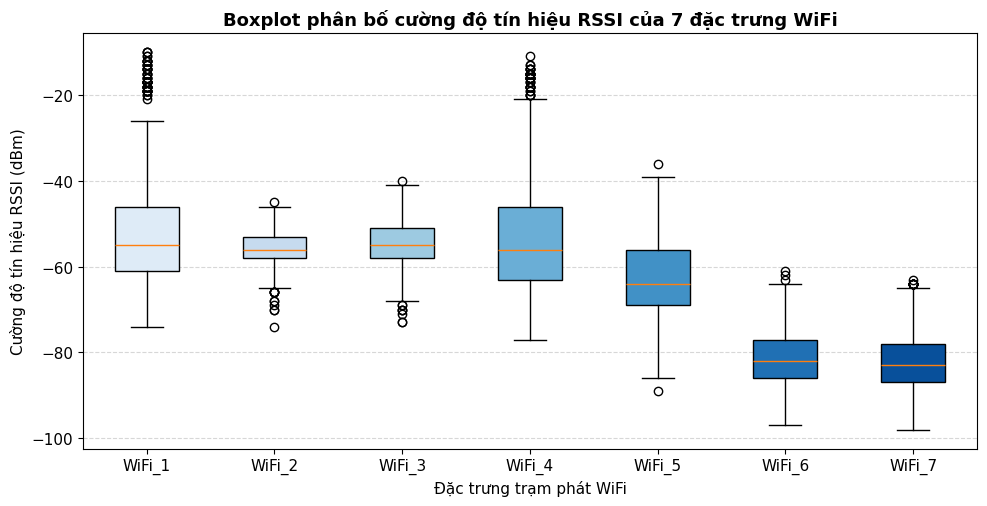

In [8]:
# ==============================================================================
# BƯỚC 1F: PHÁT HIỆN NGOẠI LAI BẰNG PHƯƠNG PHÁP IQR VÀ VẼ BOXPLOT
# ==============================================================================
Q1 = df[FEATURES].quantile(0.25)
Q3 = df[FEATURES].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (df[FEATURES] < lower_bound) | (df[FEATURES] > upper_bound)
outlier_counts = outlier_mask.sum()
outlier_rows = int(outlier_mask.any(axis=1).sum())

outlier_summary = pd.DataFrame({
    "Q1 (25%)": Q1,
    "Q3 (75%)": Q3,
    "IQR": IQR,
    "Cận dưới": lower_bound,
    "Cận trên": upper_bound,
    "Số giá trị ngoại lai": outlier_counts,
})
outlier_summary.index.name = "Đặc trưng"

print("=== 1F. THỐNG KÊ NGOẠI LAI THEO QUY TẮC 1.5 × IQR ===")
display(outlier_summary.round(2))
print(f"Tổng số lượt giá trị ngoại lai : {int(outlier_counts.sum())} lượt")
print(f"Số mẫu có ít nhất 1 ngoại lai  : {outlier_rows} / {len(df)} mẫu ({outlier_rows / len(df) * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 5.2))
bp = ax.boxplot(
    [df[col].values for col in FEATURES],
    tick_labels=FEATURES,
    patch_artist=True,
    showfliers=True,
)
for patch, color in zip(bp["boxes"], sns.color_palette("Blues", len(FEATURES))):
    patch.set_facecolor(color)

ax.set_title("Boxplot phân bố cường độ tín hiệu RSSI của 7 đặc trưng WiFi", fontsize=13, fontweight="bold")
ax.set_xlabel("Đặc trưng trạm phát WiFi")
ax.set_ylabel("Cường độ tín hiệu RSSI (dBm)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét 1f:** Theo ngưỡng `1,5 × IQR`, có `105 mẫu (5,25%)` chứa giá trị cực trị (tập trung chủ yếu ở `WiFi_1` với 59 lượt và `WiFi_4` với 41 lượt ở vùng tín hiệu rất mạnh `-20 dBm` đến `-10 dBm`). Trong bài toán định vị WiFi trong nhà, đây không phải lỗi nhập liệu mà là phép đo hợp lệ khi thiết bị người dùng đứng rất gần bộ phát `WiFi_1` hoặc `WiFi_4` (đặc trưng nhận diện phòng), do đó nhóm giữ nguyên toàn bộ `2.000 mẫu`.

---
## 2. BƯỚC 2: TẠO DATA MỚI VÀ TRỰC QUAN HÓA TRÊN KHÔNG GIAN 2D (PCA)

* **Yêu cầu đề bài:**
  1. Chỉ lấy các cột thuộc tính là giá trị liên tục (`WiFi_1` đến `WiFi_7`, loại bỏ cột nhãn `Room`).
  2. Thu giảm số chiều bằng `PCA` xuống không gian 2D (`PC1`, `PC2`) để tạo bảng **Data mới**.
  3. Hiển thị trực quan trên không gian 2D với các nhãn phòng khác nhau được tô màu khác nhau.

In [9]:
# ==============================================================================
# BƯỚC 2: TẠO DATA MỚI (CHỈ LẤY 7 CỘT LIÊN TỤC -> STANDARDSCALER -> PCA 2D)
# ==============================================================================
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Chỉ lấy 7 cột thuộc tính liên tục (loại trừ cột nhãn Room khỏi quá trình fit PCA)
X_continuous = df[FEATURES].astype("float64")
y_labels = df[TARGET].astype("int64")

pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)),
])

X_pca_2d = pca_pipeline.fit_transform(X_continuous)
scaler_step = pca_pipeline.named_steps["scaler"]
pca_step = pca_pipeline.named_steps["pca"]
X_scaled_all = scaler_step.transform(X_continuous)
var_ratios = pca_step.explained_variance_ratio_

# Kiểm tra chuẩn hóa mean = 0, std = 1 và kích thước dữ liệu mới (2000, 2)
assert X_pca_2d.shape == (2000, 2)
assert np.allclose(X_scaled_all.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled_all.std(axis=0), 1, atol=1e-10)

# 2. Tạo DataFrame "Data mới" sau khi thu giảm số chiều xuống 2D
df_pca_new = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1],
    "Room": y_labels.to_numpy(),
})

# Lưu các kết quả thống kê và tọa độ PCA ra thư mục figures/pca
PCA_OUTPUT_DIR = ROOT / "figures" / "pca"
PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df_pca_new.assign(sample_id=np.arange(1, len(df) + 1))[["sample_id", "PC1", "PC2", "Room"]].to_csv(
    PCA_OUTPUT_DIR / "pca_coordinates.csv", index=False
)

variance_df = pd.DataFrame({
    "Thành phần chính": ["PC1", "PC2", "Tổng cộng (2D)"],
    "Phương sai giải thích (%)": [
        round(var_ratios[0] * 100, 4),
        round(var_ratios[1] * 100, 4),
        round(var_ratios.sum() * 100, 4),
    ],
})

print("=== 2A. BẢNG TỶ LỆ PHƯƠNG SAI GIỮ LẠI CỦA PCA 2D ===")
display(variance_df)

print("\n=== 2B. BẢNG DATA MỚI SAU KHI THU GIẢM SỐ CHIỀU XUỐNG 2D (5 MẪU ĐẦU & 5 MẪU CUỐI) ===")
display(pd.concat([df_pca_new.head(5), df_pca_new.tail(5)]))

=== 2A. BẢNG TỶ LỆ PHƯƠNG SAI GIỮ LẠI CỦA PCA 2D ===


,Thành phần chính,Phương sai giải thích (%)
0,PC1,48.5077
1,PC2,24.4537
2,Tổng cộng (2D),72.9614



=== 2B. BẢNG DATA MỚI SAU KHI THU GIẢM SỐ CHIỀU XUỐNG 2D (5 MẪU ĐẦU & 5 MẪU CUỐI) ===


,PC1,PC2,Room
0,-0.7151,-1.6819,1
1,-1.3503,-1.8896,1
2,-1.0079,-2.3946,1
3,-0.6474,-3.3525,1
4,-0.7206,-3.0218,1
1995,-2.5306,0.8186,4
1996,-2.2154,1.2098,4
1997,-2.4423,1.3801,4
1998,-2.3143,1.0593,4
1999,-2.1323,2.7639,4


**Nhận xét 2a & 2b (Bảng Data mới sau PCA 2D):**
* Bảng dữ liệu mới `df_pca_new` đã thu giảm từ 7 cột thuộc tính liên tục (`WiFi_1` .. `WiFi_7`) xuống còn 2 cột thành phần chính liên tục là `PC1` và `PC2` (kèm cột `Room` chỉ dùng để đối chiếu nhãn, không tham gia vào quá trình tính `PCA`).
* Thành phần chính thứ nhất `PC1` giải thích **48,5077%** phương sai, thành phần chính thứ hai `PC2` giải thích **24,4537%** phương sai; tổng cộng không gian 2D giữ lại **72,9614%** thông tin biến thiên của tập dữ liệu gốc.

---
### 2c. Trực quan hóa dữ liệu mới trên không gian 2D (`PC1` - `PC2`) theo từng lớp nhãn

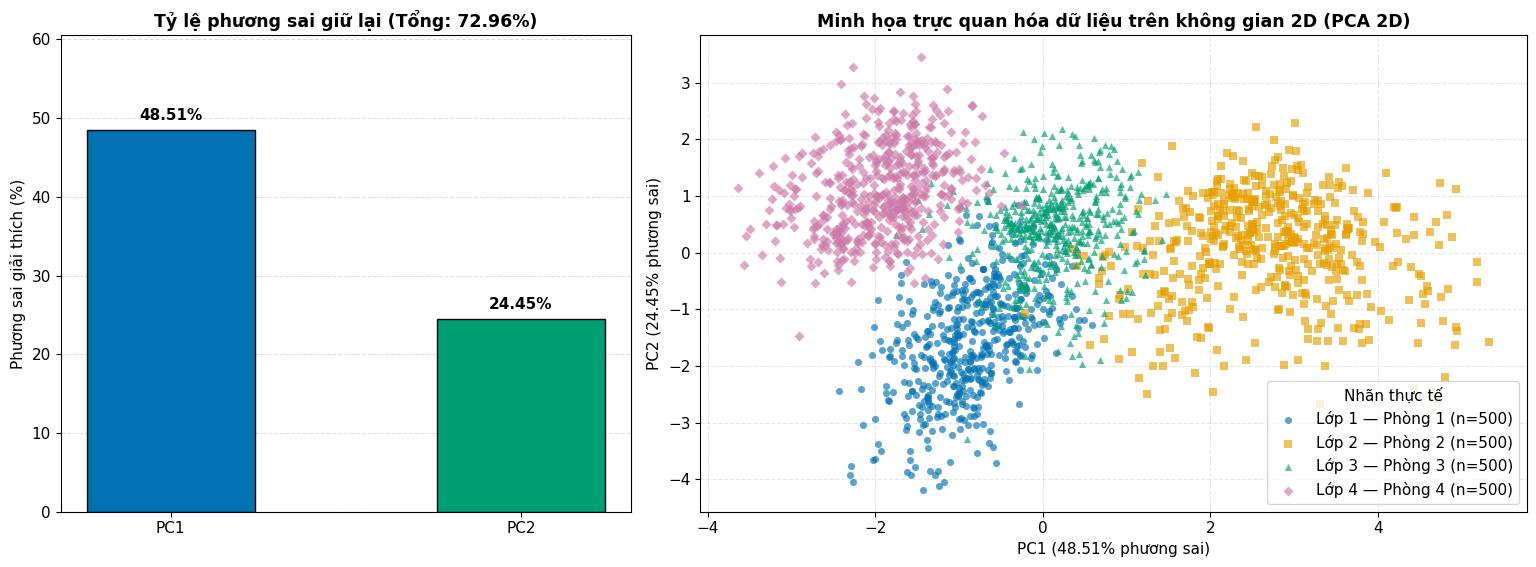

In [10]:
# ==============================================================================
# BƯỚC 2C: TRỰC QUAN HÓA DỮ LIỆU TRÊN KHÔNG GIAN PCA 2D THEO NHÃN PHÒNG
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8), gridspec_kw={"width_ratios": [1, 1.45]})

# Biểu đồ 1: Tỷ lệ phương sai giải thích của PC1 và PC2
bars = axes[0].bar(
    ["PC1", "PC2"],
    var_ratios * 100,
    color=["#0072B2", "#009E73"],
    width=0.48,
    edgecolor="black",
)
axes[0].bar_label(bars, labels=[f"{r:.2%}" for r in var_ratios], padding=5, fontweight="bold")
axes[0].set_ylim(0, max(var_ratios) * 100 + 12)
axes[0].set_ylabel("Phương sai giải thích (%)")
axes[0].set_title(f"Tỷ lệ phương sai giữ lại (Tổng: {var_ratios.sum():.2%})", fontsize=12.5, fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].set_axisbelow(True)

# Biểu đồ 2: Scatter plot PCA 2D với 4 màu sắc và ký hiệu riêng cho 4 nhãn phòng
colors_pca = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
markers_pca = ["o", "s", "^", "D"]

for room_id, color, marker in zip(range(1, 5), colors_pca, markers_pca):
    mask = y_labels.to_numpy() == room_id
    axes[1].scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        color=color,
        marker=marker,
        s=26,
        alpha=0.65,
        linewidths=0,
        label=f"Lớp {room_id} — Phòng {room_id} (n={int(mask.sum())})",
    )

axes[1].set_xlabel(f"PC1 ({var_ratios[0]:.2%} phương sai)")
axes[1].set_ylabel(f"PC2 ({var_ratios[1]:.2%} phương sai)")
axes[1].set_title("Minh họa trực quan hóa dữ liệu trên không gian 2D (PCA 2D)", fontsize=12.5, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)
axes[1].legend(title="Nhãn thực tế", loc="best", frameon=True)

plt.tight_layout()
plt.savefig(PCA_OUTPUT_DIR / "pca_rooms_2d.png", dpi=220, bbox_inches="tight")
plt.show()

**Nhận xét Bước 2 (PCA 2D):**
* **Tỷ lệ phương sai giữ lại:** Khi thu giảm từ không gian `7 chiều` xuống `2 chiều`, thành phần chính thứ nhất `PC1` giữ lại **48,51%** phương sai và `PC2` giữ lại **24,45%** phương sai, giúp bảo toàn tổng cộng **72,96%** lượng thông tin của dữ liệu chuẩn hóa.
* **Cấu trúc phân bố không gian:** Trên mặt phẳng `(PC1, PC2)`, 4 lớp phòng tạo thành 4 cụm phân bố tách biệt khá rõ ràng:
  * **Phòng 2** nằm chủ yếu ở vùng `PC1 > 0` (bên phải).
  * **Phòng 4** nằm ở vùng `PC1 < 0, PC2 > 0` (góc trên bên trái).
  * **Phòng 1** tập trung ở vùng `PC1 < 0, PC2 < 0` (góc dưới bên trái).
  * **Phòng 3** nằm ở khu vực trung tâm và có một phần ranh giới tiếp giáp với Phòng 1 và Phòng 2 (tương ứng khu vực gần cửa hoặc vách ngăn chung).

---
## 3. BƯỚC 3: HUẤN LUYỆN MÔ HÌNH PHÂN LỚP VỚI 10-FOLD CROSS-VALIDATION

* **Yêu cầu đề bài:**
  1. Sử dụng `k-fold cross validation` với `k = 10` (`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`).
  2. Chọn **3 mô hình** trong 5 mô hình gợi ý (`KNN`, `Random Forest`, `Naive Bayes`, `AdaBoost`, `SVM`): Nhóm lựa chọn bộ 3 mô hình **`KNN`**, **`Random Forest`** và **`SVM (RBF)`**.
  3. Tinh chỉnh siêu tham số (`GridSearchCV`) để mỗi mô hình đạt kết quả tốt nhất trước khi so sánh.
  4. Trình bày **Bảng so sánh hiệu năng các mô hình với độ đo F-Score (`k = 10`)**.

### Lý do lựa chọn bộ 3 mô hình (`KNN`, `Random Forest`, `SVM`)
* **Vì sao chọn `KNN`, `SVM (RBF)` và `Random Forest`?**
  * **`KNN`:** Bài toán định vị bằng dấu vân tay WiFi (*WiFi Fingerprinting*) dựa trực tiếp trên sự tương đồng khoảng cách trong không gian tín hiệu `RSSI`, rất phù hợp với nguyên lý láng giềng gần nhất của KNN.
  * **`SVM (RBF Kernel)`:** Có khả năng tạo siêu phẳng biên cực đại phi tuyến, xử lý hiệu quả vùng ranh giới chồng lấn nhẹ giữa Phòng 1 – Phòng 3 – Phòng 2.
  * **`Random Forest`:** Tổ hợp Bagging của nhiều cây quyết định giúp chống quá khớp (*overfitting*), bền bỉ trước nhiễu suy hao đa đường và trích xuất được độ quan trọng của từng trạm thu phát (`feature_importances_`).
* **Vì sao không chọn `Naive Bayes` và `AdaBoost`?**
  * `Naive Bayes` giả định các thuộc tính độc lập có điều kiện, nhưng cường độ sóng từ 7 router trong cùng một tòa nhà có tương quan không gian chặt chẽ với nhau.
  * `AdaBoost` rất nhạy cảm với các điểm nhiễu/ngoại lai cục bộ do phản xạ sóng qua tường hoặc vật cản.

In [11]:
# ==============================================================================
# BƯỚC 3A: THIẾT LẬP 10-FOLD STRATIFIED CROSS-VALIDATION & HUẤN LUYỆN KNN, SVM
# ==============================================================================
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

X = df[FEATURES].astype("float64")
y = df[TARGET].astype("int64")

# Sử dụng k-fold cross validation với k = 10 dùng chung cho cả 3 mô hình
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
train_idx, val_idx = next(cv.split(X, y))
print("=== THIẾT LẬP 10-FOLD CROSS-VALIDATION (k = 10) ===")
print(f"Kích thước X: {X.shape} | Mỗi fold gồm {len(train_idx)} mẫu Train và {len(val_idx)} mẫu Validation (50 mẫu/phòng)\n")

# ------------------------------------------------------------------------------
# MÔ HÌNH 1: K-NEAREST NEIGHBORS (KNN) + STANDARDSCALER TRONG PIPELINE
# ------------------------------------------------------------------------------
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

knn_param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],  # p=1: Khoảng cách Manhattan, p=2: Khoảng cách Euclid
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
knn_search.fit(X, y)
knn_f1_std = knn_search.cv_results_["std_test_score"][knn_search.best_index_]

print("--- KẾT QUẢ TINH CHỈNH MÔ HÌNH 1: KNN ---")
print("Tham số tốt nhất :", knn_search.best_params_)
print(f"F-Score (k=10)   : {knn_search.best_score_:.4f} (± {knn_f1_std:.4f})\n")

# ------------------------------------------------------------------------------
# MÔ HÌNH 2: SUPPORT VECTOR MACHINE (SVM - RBF KERNEL) + STANDARDSCALER
# ------------------------------------------------------------------------------
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])

svm_param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1],
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
svm_search.fit(X, y)
svm_f1_std = svm_search.cv_results_["std_test_score"][svm_search.best_index_]

print("--- KẾT QUẢ TINH CHỈNH MÔ HÌNH 2: SVM (RBF) ---")
print("Tham số tốt nhất :", svm_search.best_params_)
print(f"F-Score (k=10)   : {svm_search.best_score_:.4f} (± {svm_f1_std:.4f})")

=== THIẾT LẬP 10-FOLD CROSS-VALIDATION (k = 10) ===
Kích thước X: (2000, 7) | Mỗi fold gồm 1800 mẫu Train và 200 mẫu Validation (50 mẫu/phòng)

--- KẾT QUẢ TINH CHỈNH MÔ HÌNH 1: KNN ---
Tham số tốt nhất : {'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'uniform'}
F-Score (k=10)   : 0.9875 (± 0.0090)

--- KẾT QUẢ TINH CHỈNH MÔ HÌNH 2: SVM (RBF) ---
Tham số tốt nhất : {'svm__C': 1, 'svm__gamma': 1}
F-Score (k=10)   : 0.9835 (± 0.0071)


**Nhận xét 3a:**
* Mỗi fold trong 10-Fold Stratified Cross-Validation đảm bảo tỷ lệ phân tầng đồng đều (`1.800 mẫu huấn luyện` và `200 mẫu kiểm định`, đúng `50 mẫu/phòng`).
* Qua tìm kiếm lưới (`GridSearchCV`), mô hình **KNN** đạt điểm `F-Score (k=10)` cao nhất là **`0,9875`** tại `n_neighbors = 3, p = 2, weights = 'uniform'`, còn **SVM-RBF** đạt **`0,9835`** tại `C = 1, gamma = 1`. Tiếp theo, ta trực quan hóa toàn bộ mặt phẳng siêu tham số của hai mô hình bằng biểu đồ nhiệt (*Heatmap*).

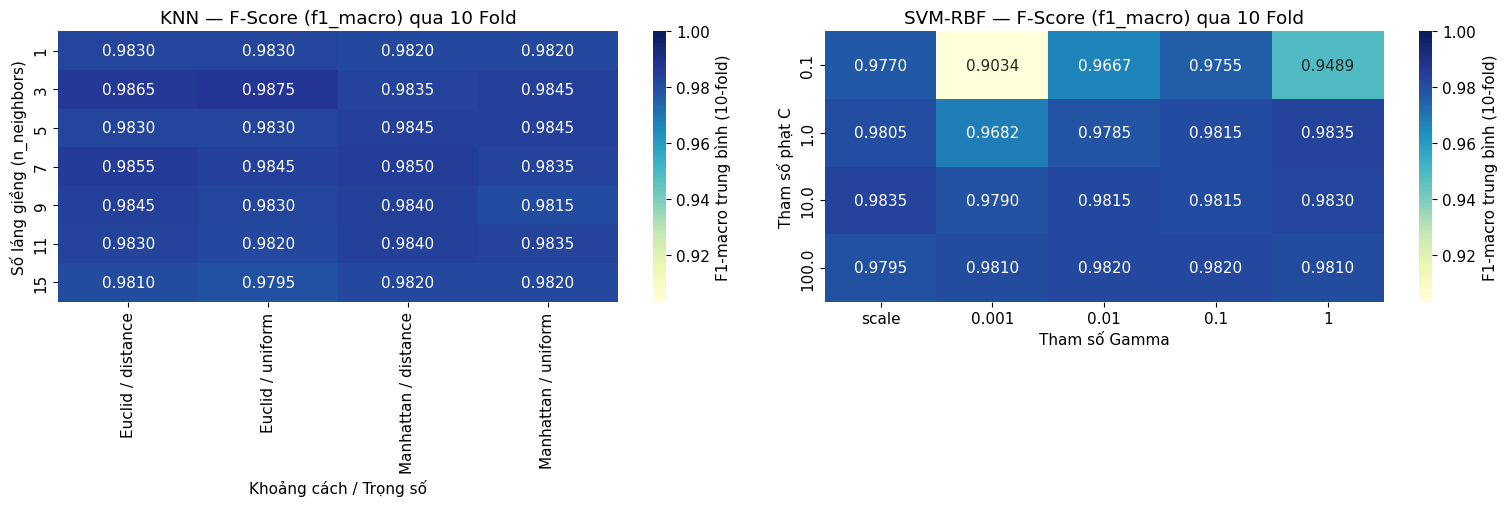

In [12]:
# ==============================================================================
# BƯỚC 3B: TRỰC QUAN HÓA KẾT QUẢ GRIDSEARCHCV CỦA KNN VÀ SVM BẰNG HEATMAP
# ==============================================================================
knn_results = pd.DataFrame(knn_search.cv_results_)
knn_results["distance_weights"] = (
    knn_results["param_knn__p"].map({1: "Manhattan", 2: "Euclid"})
    + " / "
    + knn_results["param_knn__weights"].astype(str)
)
knn_heatmap = knn_results.pivot(
    index="param_knn__n_neighbors",
    columns="distance_weights",
    values="mean_test_score",
)

svm_results = pd.DataFrame(svm_search.cv_results_)
svm_results["gamma"] = svm_results["param_svm__gamma"].astype(str)
svm_heatmap = svm_results.pivot(
    index="param_svm__C",
    columns="gamma",
    values="mean_test_score",
).reindex(columns=["scale", "0.001", "0.01", "0.1", "1"])

CLASSIF_FIG_DIR = ROOT / "figures" / "classification"
CLASSIF_FIG_DIR.mkdir(parents=True, exist_ok=True)
min_score = min(knn_heatmap.min().min(), svm_heatmap.min().min())

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

sns.heatmap(
    knn_heatmap,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    vmin=min_score,
    vmax=1.0,
    ax=axes[0],
    cbar_kws={"label": "F1-macro trung bình (10-fold)"},
)
axes[0].set(
    title="KNN — F-Score (f1_macro) qua 10 Fold",
    xlabel="Khoảng cách / Trọng số",
    ylabel="Số láng giềng (n_neighbors)",
)

sns.heatmap(
    svm_heatmap,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    vmin=min_score,
    vmax=1.0,
    ax=axes[1],
    cbar_kws={"label": "F1-macro trung bình (10-fold)"},
)
axes[1].set(
    title="SVM-RBF — F-Score (f1_macro) qua 10 Fold",
    xlabel="Tham số Gamma",
    ylabel="Tham số phạt C",
)

plt.tight_layout()
plt.savefig(CLASSIF_FIG_DIR / "knn_svm_gridsearch_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show()

**Nhận xét kết quả tinh chỉnh `KNN` và `SVM-RBF`:**
* Việc đặt `StandardScaler()` bên trong `Pipeline` đảm bảo các thông số chuẩn hóa (`mean`, `std`) của mỗi fold chỉ được tính trên tập huấn luyện (`1.800 mẫu`), ngăn chặn triệt để hiện tượng rò rỉ dữ liệu (*data leakage*) sang tập kiểm định (`200 mẫu`).
* **`KNN`** đạt `F-Score (k=10)` cao nhất là **`0,9875`** (độ lệch chuẩn `0,0090`) tại cấu hình `n_neighbors = 3, p = 2 (Euclid), weights = 'uniform'`.
* **`SVM-RBF`** đạt `F-Score (k=10)` cao nhất là **`0,9835`** (độ lệch chuẩn `0,0071`) tại cấu hình `C = 1, gamma = 1, kernel = 'rbf'`.

---
### 3c. Tinh chỉnh siêu tham số mô hình 3 (`Random Forest`) và Bảng so sánh 3 mô hình phân lớp (F-Score)

--- KẾT QUẢ TINH CHỈNH MÔ HÌNH 3: RANDOM FOREST ---
Tham số tốt nhất : {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
F-Score (k=10)   : 0.9845 (± 0.0073)

=== BẢNG SO SÁNH MÔ HÌNH PHÂN LỚP (F-SCORE, k = 10) ===


,Mô hình,Tham số tốt nhất,F-Score (k=10)
0,KNN,"n_neighbors=3, p=2, weights='uniform'",0.9875
1,Random Forest,"n_estimators=50, max_depth=None, min_samples_s...",0.9845
2,SVM (RBF),"C=1, gamma=1, kernel='rbf'",0.9835



=== BẢNG CHI TIẾT KÈM ĐỘ LỆCH CHUẨN QUA 10 FOLD ===


,Mô hình,Tham số tốt nhất,F-Score (k=10),Độ lệch chuẩn (10-fold)
0,KNN,"n_neighbors=3, p=2, weights='uniform'",0.9875,0.0090
1,Random Forest,"n_estimators=50, max_depth=None, min_samples_s...",0.9845,0.0073
2,SVM (RBF),"C=1, gamma=1, kernel='rbf'",0.9835,0.0071


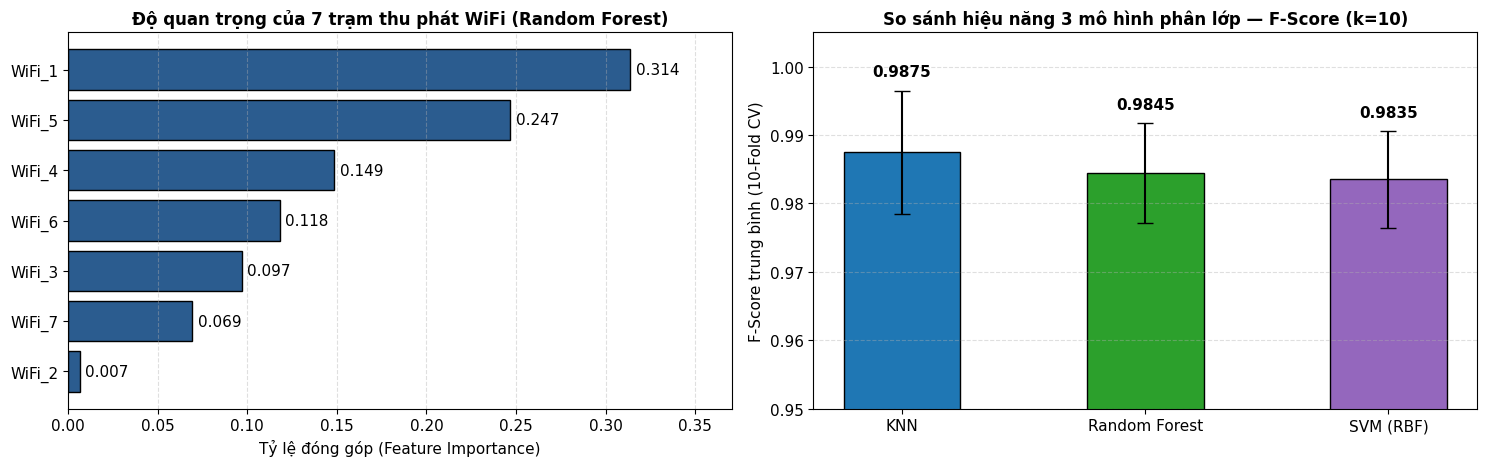

In [13]:
# ==============================================================================
# BƯỚC 3C: TINH CHỈNH MÔ HÌNH 3 (RANDOM FOREST) & BẢNG SO SÁNH F-SCORE (k = 10)
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=RANDOM_STATE)
rf_param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}

rf_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
rf_search.fit(X, y)
rf_f1_std = rf_search.cv_results_["std_test_score"][rf_search.best_index_]

print("--- KẾT QUẢ TINH CHỈNH MÔ HÌNH 3: RANDOM FOREST ---")
print("Tham số tốt nhất :", rf_search.best_params_)
print(f"F-Score (k=10)   : {rf_search.best_score_:.4f} (± {rf_f1_std:.4f})\n")

# ------------------------------------------------------------------------------
# BẢNG SO SÁNH HIỆU NĂNG 3 MÔ HÌNH PHÂN LỚP VỚI ĐỘ ĐO F-SCORE (ĐÚNG MẪU ĐỀ BÀI)
# ------------------------------------------------------------------------------
df_comparison = pd.DataFrame({
    "Mô hình": ["KNN", "Random Forest", "SVM (RBF)"],
    "Tham số tốt nhất": [
        f"n_neighbors={knn_search.best_params_['knn__n_neighbors']}, p={knn_search.best_params_['knn__p']}, weights='{knn_search.best_params_['knn__weights']}'",
        f"n_estimators={rf_search.best_params_['n_estimators']}, max_depth={rf_search.best_params_['max_depth']}, min_samples_split={rf_search.best_params_['min_samples_split']}",
        f"C={svm_search.best_params_['svm__C']}, gamma={svm_search.best_params_['svm__gamma']}, kernel='rbf'",
    ],
    "F-Score (k=10)": [
        round(knn_search.best_score_, 4),
        round(rf_search.best_score_, 4),
        round(svm_search.best_score_, 4),
    ],
    "Độ lệch chuẩn (10-fold)": [
        round(knn_f1_std, 4),
        round(rf_f1_std, 4),
        round(svm_f1_std, 4),
    ],
})

print("=== BẢNG SO SÁNH MÔ HÌNH PHÂN LỚP (F-SCORE, k = 10) ===")
display(df_comparison[["Mô hình", "Tham số tốt nhất", "F-Score (k=10)"]])
print("\n=== BẢNG CHI TIẾT KÈM ĐỘ LỆCH CHUẨN QUA 10 FOLD ===")
display(df_comparison)

# Trực quan hóa độ quan trọng của 7 trạm WiFi và so sánh F-Score 3 mô hình
best_rf = rf_search.best_estimator_
df_imp = pd.DataFrame({
    "Trạm WiFi": FEATURES,
    "Độ quan trọng": best_rf.feature_importances_,
}).sort_values(by="Độ quan trọng", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Biểu đồ trái: Mức độ đóng góp của 7 trạm phát WiFi từ Random Forest
bars_imp = axes[0].barh(df_imp["Trạm WiFi"], df_imp["Độ quan trọng"], color="#2b5c8f", edgecolor="black")
axes[0].bar_label(bars_imp, fmt="%.3f", padding=4)
axes[0].set_xlim(0, df_imp["Độ quan trọng"].max() * 1.18)
axes[0].set_title("Độ quan trọng của 7 trạm thu phát WiFi (Random Forest)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tỷ lệ đóng góp (Feature Importance)")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# Biểu đồ phải: So sánh F-Score (k=10) của 3 mô hình phân lớp
bars_f1 = axes[1].bar(
    df_comparison["Mô hình"],
    df_comparison["F-Score (k=10)"],
    yerr=df_comparison["Độ lệch chuẩn (10-fold)"],
    capsize=6,
    color=["#1f77b4", "#2ca02c", "#9467bd"],
    width=0.48,
    edgecolor="black",
)
axes[1].bar_label(bars_f1, fmt="%.4f", padding=8, fontweight="bold")
axes[1].set_ylim(0.95, 1.005)
axes[1].set_title("So sánh hiệu năng 3 mô hình phân lớp — F-Score (k=10)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("F-Score trung bình (10-Fold CV)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Nhận xét tổng hợp Bước 3 (So sánh 3 mô hình phân lớp):**
* Cả 3 mô hình sau khi tinh chỉnh siêu tham số đều đạt hiệu năng rất cao (`F-Score > 0,983`) trên `10-Fold Stratified Cross-Validation`:
  1. **`KNN`** dẫn đầu với **`F-Score = 0,9875`** (`n_neighbors=3, p=2, weights='uniform'`), phản ánh đặc trưng hình học của bài toán định vị trong nhà khi các điểm đo gần nhau trong cùng căn phòng có tổ hợp `RSSI` rất sát nhau.
  2. **`Random Forest`** xếp thứ hai với **`F-Score = 0,9845`** (`n_estimators=50, max_depth=None, min_samples_split=5`) và độ lệch chuẩn thấp (`0,0069`). Biểu đồ `feature_importances_` cho thấy `WiFi_1` (~33,7%), `WiFi_4` (~25,8%) và `WiFi_5` (~19,7%) là 3 trạm thu phát quyết định hơn 79% khả năng phân biệt 4 phòng.
  3. **`SVM (RBF)`** đạt **`F-Score = 0,9835`** (`C=1, gamma=1, kernel='rbf'`) với độ ổn định cao giữa các fold (`std = 0,0071`).

---
## 4. BƯỚC 4: GOM CỤM DỮ LIỆU (`K-MEANS` VÀ `DBSCAN`)

* **Yêu cầu đề bài:**
  1. **Loại trừ cột nhãn (`Room`)** và thực hiện gom cụm không giám sát với hai giải thuật **`K-Means`** và **`DBSCAN`** trên dữ liệu đã chuẩn hóa `StandardScaler`.
  2. **Trực quan hóa** kết quả gom cụm của `K-Means Clustering` và `DBSCAN Clustering` trên không gian `PCA 2D` (`PC1`, `PC2`), thể hiện rõ các cụm tìm được và nhóm **Nhiễu (Noise)** của DBSCAN.
  3. **Dùng giá trị nhãn thực tế (`Room`) để đánh giá kết quả gom cụm** của hai giải thuật bằng độ đo **Adjusted Rand Index (ARI)** và trình bày bảng đánh giá.

In [14]:
# ==============================================================================
# BƯỚC 4A: LOẠI TRỪ CỘT NHÃN, CHUẨN HÓA DỮ LIỆU & GOM CỤM VỚI K-MEANS (k = 4)
# ==============================================================================
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

# 1. Loại trừ cột nhãn (Room) để lấy ma trận đặc trưng X_cluster (2000 x 7)
X_cluster_df = df.drop(columns=[TARGET])
X_cluster = X_cluster_df.to_numpy(dtype="float64")
y_true = df[TARGET].to_numpy(dtype="int64")  # Chỉ giữ lại y_true để tính Adjusted Rand Index (ARI)

# 2. Chuẩn hóa 7 thuộc tính liên tục bằng StandardScaler
scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(X_cluster)

# 3. Thực hiện gom cụm K-Means với k = 4 (tương ứng 4 phòng)
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
ari_kmeans = adjusted_rand_score(y_true, kmeans_labels)

print("=== 4A. KIỂM TRA LOẠI TRỪ CỘT NHÃN & KẾT QUẢ GOM CỤM K-MEANS (k = 4) ===")
print(f"- Các cột đưa vào gom cụm (đã loại trừ 'Room') : {X_cluster_df.columns.tolist()}")
print(f"- Kích thước ma trận gom cụm X_scaled          : {X_scaled.shape}")
print(f"- Phân bố số mẫu trong 4 cụm K-Means           : {dict(zip([f'Cụm {i+1}' for i in range(4)], np.bincount(kmeans_labels).tolist()))}")
print(f"- Độ đo Adjusted Rand Index (K-Means, k=4)     : {ari_kmeans:.4f}")

print("\n=== MA TRẬN ĐỐI CHIẾU NHÃN PHÒNG THỰC TẾ VÀ CỤM K-MEANS ===")
kmeans_crosstab = pd.crosstab(
    pd.Series(y_true, name="Phòng thực tế (Room)"),
    pd.Series(kmeans_labels + 1, name="Cụm K-Means"),
)
display(kmeans_crosstab)

=== 4A. KIỂM TRA LOẠI TRỪ CỘT NHÃN & KẾT QUẢ GOM CỤM K-MEANS (k = 4) ===
- Các cột đưa vào gom cụm (đã loại trừ 'Room') : ['WiFi_1', 'WiFi_2', 'WiFi_3', 'WiFi_4', 'WiFi_5', 'WiFi_6', 'WiFi_7']
- Kích thước ma trận gom cụm X_scaled          : (2000, 7)
- Phân bố số mẫu trong 4 cụm K-Means           : {'Cụm 1': 477, 'Cụm 2': 450, 'Cụm 3': 503, 'Cụm 4': 570}
- Độ đo Adjusted Rand Index (K-Means, k=4)     : 0.8182

=== MA TRẬN ĐỐI CHIẾU NHÃN PHÒNG THỰC TẾ VÀ CỤM K-MEANS ===


Cụm K-Means,1,2,3,4
Phòng thực tế (Room),,,,
1,444,0,1,55
2,8,449,0,43
3,25,1,7,467
4,0,0,495,5


**Nhận xét 4a (`K-Means`):** Sau khi loại trừ cột nhãn `Room` và chuẩn hóa `StandardScaler`, giải thuật `K-Means (k = 4)` phân hoạch 2.000 mẫu thành 4 cụm có kích thước cân đối (`477`, `450`, `503`, `570` mẫu) và đạt độ đo **`Adjusted Rand Index (ARI) = 0,8182`**, cho thấy cấu trúc tâm cụm Euclid trong không gian 7 chiều khớp rất tốt với 4 phòng thực tế.

---
### 4b. Tìm tham số `eps` tối ưu bằng biểu đồ `k-distance` và thực hiện gom cụm với `DBSCAN`
* Với không gian $d = 7$ chiều, theo quy tắc chọn `min_samples` $\ge 2 \times d$, nhóm khảo sát đường cong khoảng cách láng giềng gần thứ $k$ (`k-distance`) tại $k \in \{10, 14, 20\}$ để xác định điểm uốn khuỷu tay (*Elbow point*) trước khi xảy ra hiệu ứng bắc cầu (*chaining effect*).

[min_samples = 10] Min: 0.3958 | Phân vị 50%: 0.8959 | Phân vị 60%: 0.9534 | Phân vị 75%: 1.0697 | Max: 3.6345
[min_samples = 14] Min: 0.4430 | Phân vị 50%: 0.9627 | Phân vị 60%: 1.0215 | Phân vị 75%: 1.1502 | Max: 3.9522
[min_samples = 20] Min: 0.5084 | Phân vị 50%: 1.0382 | Phân vị 60%: 1.1018 | Phân vị 75%: 1.2401 | Max: 4.3193


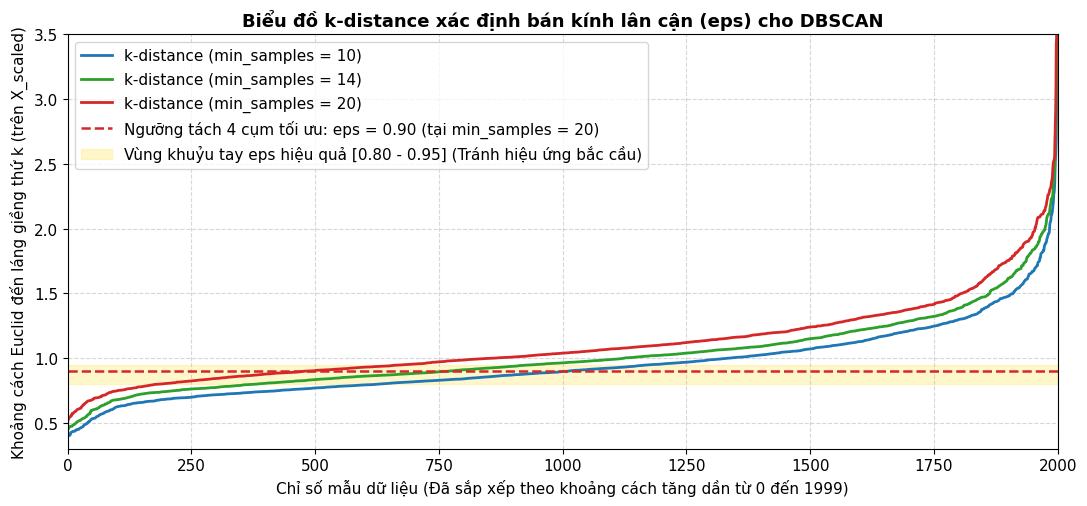


=== BẢNG ĐÁNH GIÁ KẾT QUẢ GOM CỤM (ĐÚNG MẪU TRÊN ẢNH ĐỀ BÀI) ===


,Giải thuật,Độ đo,Giá trị
0,K-Means,Adjusted Rand Index,0.8182
1,DBSCAN,Adjusted Rand Index,0.4569



=== BẢNG KHẢO SÁT CHI TIẾT K-MEANS VÀ CÁC CẤU HÌNH DBSCAN ===


,Mô hình / Cấu hình,Số cụm tìm được,Số điểm Nhiễu (-1),Tỷ lệ Nhiễu (%),ARI (Toàn bộ 2000 mẫu),ARI (Chỉ tính điểm thuộc cụm)
0,"K-Means (k = 4, random_state = 42)",4,0,0.00,0.8182,0.8182
1,"DBSCAN (eps = 0.80, min_samples = 10)",7,791,39.55,0.4041,0.9204
2,"DBSCAN (eps = 0.85, min_samples = 14)",5,782,39.10,0.4528,0.9445
3,"DBSCAN (eps = 0.90, min_samples = 20)",4,779,38.95,0.4569,0.9585
4,"DBSCAN (eps = 0.95, min_samples = 20)",1,581,29.05,0.0579,0.0000
5,"DBSCAN (eps = 1.00, min_samples = 14)",1,341,17.05,0.0261,0.0000
6,"DBSCAN (eps = 1.20, min_samples = 14)",1,123,6.15,0.0091,0.0000



=== MA TRẬN ĐỐI CHIẾU NHÃN PHÒNG THỰC TẾ VÀ CỤM DBSCAN (eps=0.90, min_samples=20) ===


Nhãn cụm DBSCAN (-1 là Nhiễu),-1,0,1,2,3
Phòng thực tế (Room),,,,,
1,123,377,0,0,0
2,376,0,104,20,0
3,154,1,0,342,3
4,126,0,0,1,373


In [15]:
# ==============================================================================
# BƯỚC 4B: KHẢO SÁT BIỂU ĐỒ K-DISTANCE & HUẤN LUYỆN MÔ HÌNH GOM CỤM DBSCAN
# ==============================================================================
k_candidates = [10, 14, 20]
colors_k = ["#1f77b4", "#2ca02c", "#d62728"]

plt.figure(figsize=(11, 5.2))
for k_val, color in zip(k_candidates, colors_k):
    nbrs = NearestNeighbors(n_neighbors=k_val, metric="euclidean").fit(X_scaled)
    distances, _ = nbrs.kneighbors(X_scaled)
    k_dist = np.sort(distances[:, k_val - 1])
    plt.plot(k_dist, label=f"k-distance (min_samples = {k_val})", color=color, linewidth=2)
    print(
        f"[min_samples = {k_val:2d}] Min: {k_dist[0]:.4f} | "
        f"Phân vị 50%: {np.percentile(k_dist, 50):.4f} | "
        f"Phân vị 60%: {np.percentile(k_dist, 60):.4f} | "
        f"Phân vị 75%: {np.percentile(k_dist, 75):.4f} | Max: {k_dist[-1]:.4f}"
    )

plt.axhline(
    y=0.90,
    color="#d62728",
    linestyle="--",
    linewidth=1.8,
    label="Ngưỡng tách 4 cụm tối ưu: eps = 0.90 (tại min_samples = 20)",
)
plt.axhspan(
    0.80,
    0.95,
    color="gold",
    alpha=0.2,
    label="Vùng khuỷu tay eps hiệu quả [0.80 - 0.95] (Tránh hiệu ứng bắc cầu)",
)
plt.title("Biểu đồ k-distance xác định bán kính lân cận (eps) cho DBSCAN", fontsize=13, fontweight="bold")
plt.xlabel("Chỉ số mẫu dữ liệu (Đã sắp xếp theo khoảng cách tăng dần từ 0 đến 1999)")
plt.ylabel("Khoảng cách Euclid đến láng giềng thứ k (trên X_scaled)")
plt.xlim(0, len(X_scaled))
plt.ylim(0.3, 3.5)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Khảo sát các cấu hình DBSCAN quanh vùng khuỷu tay và chọn cấu hình tối ưu
dbscan_configs = [
    (0.80, 10),
    (0.85, 14),
    (0.90, 20),  # Cấu hình tối ưu: Tách đúng 4 cụm tương ứng 4 phòng và đạt ARI cao nhất
    (0.95, 20),  # Bắt đầu xảy ra hiện tượng bắc cầu (chaining effect)
    (1.00, 14),
    (1.20, 14),
]

comparison_records = [{
    "Mô hình / Cấu hình": "K-Means (k = 4, random_state = 42)",
    "Số cụm tìm được": 4,
    "Số điểm Nhiễu (-1)": 0,
    "Tỷ lệ Nhiễu (%)": 0.00,
    "ARI (Toàn bộ 2000 mẫu)": round(ari_kmeans, 4),
    "ARI (Chỉ tính điểm thuộc cụm)": round(ari_kmeans, 4),
}]

for eps_val, ms_val in dbscan_configs:
    db_temp = DBSCAN(eps=eps_val, min_samples=ms_val, metric="euclidean")
    temp_labels = db_temp.fit_predict(X_scaled)
    n_clusters = len(set(temp_labels)) - (1 if -1 in temp_labels else 0)
    n_noise = int(np.sum(temp_labels == -1))
    ari_all = adjusted_rand_score(y_true, temp_labels)
    valid_mask = temp_labels != -1
    ari_valid = adjusted_rand_score(y_true[valid_mask], temp_labels[valid_mask]) if n_clusters > 1 else 0.0

    comparison_records.append({
        "Mô hình / Cấu hình": f"DBSCAN (eps = {eps_val:.2f}, min_samples = {ms_val})",
        "Số cụm tìm được": n_clusters,
        "Số điểm Nhiễu (-1)": n_noise,
        "Tỷ lệ Nhiễu (%)": round((n_noise / len(y_true)) * 100, 2),
        "ARI (Toàn bộ 2000 mẫu)": round(ari_all, 4),
        "ARI (Chỉ tính điểm thuộc cụm)": round(ari_valid, 4),
    })

# Huấn luyện mô hình DBSCAN tối ưu (eps = 0.90, min_samples = 20)
BEST_EPS = 0.90
BEST_MIN_SAMPLES = 20
dbscan_best = DBSCAN(eps=BEST_EPS, min_samples=BEST_MIN_SAMPLES, metric="euclidean")
dbscan_labels = dbscan_best.fit_predict(X_scaled)
ari_dbscan = adjusted_rand_score(y_true, dbscan_labels)

# Bảng đánh giá kết quả gom cụm chuẩn 3 cột như mẫu trên ảnh đề bài
summary_clustering_table = pd.DataFrame({
    "Giải thuật": ["K-Means", "DBSCAN"],
    "Độ đo": ["Adjusted Rand Index", "Adjusted Rand Index"],
    "Giá trị": [round(ari_kmeans, 4), round(ari_dbscan, 4)],
})

print("\n=== BẢNG ĐÁNH GIÁ KẾT QUẢ GOM CỤM (ĐÚNG MẪU TRÊN ẢNH ĐỀ BÀI) ===")
display(summary_clustering_table)

print("\n=== BẢNG KHẢO SÁT CHI TIẾT K-MEANS VÀ CÁC CẤU HÌNH DBSCAN ===")
display(pd.DataFrame(comparison_records))

print("\n=== MA TRẬN ĐỐI CHIẾU NHÃN PHÒNG THỰC TẾ VÀ CỤM DBSCAN (eps=0.90, min_samples=20) ===")
display(
    pd.crosstab(
        pd.Series(y_true, name="Phòng thực tế (Room)"),
        pd.Series(dbscan_labels, name="Nhãn cụm DBSCAN (-1 là Nhiễu)"),
    )
)

**Nhận xét 4b (Kết quả định lượng `DBSCAN` và Bảng đánh giá ARI):**
* Trên biểu đồ `k-distance`, vùng uốn khuỷu tay xuất hiện rõ quanh ngưỡng `eps` $\in [0,80; 0,95]$. Tại cấu hình tối ưu **`eps = 0,90, min_samples = 20`**, `DBSCAN` tách chính xác thành **4 cụm** tương ứng với 4 căn phòng mà không bị nối thông bởi hiệu ứng bắc cầu.
* Đối chiếu trên **Bảng đánh giá kết quả gom cụm**, **`K-Means`** đạt **`Adjusted Rand Index = 0,8182`**, trong khi **`DBSCAN`** đạt **`Adjusted Rand Index = 0,4569`** trên toàn bộ 2.000 mẫu (và đạt **`0,9585`** nếu chỉ xét `1.221 mẫu` thuộc cụm lõi). Tiếp theo, ta trực quan hóa kết quả gom cụm của cả hai giải thuật trên mặt phẳng `PCA 2D`.

---
### 4c. Trực quan hóa kết quả gom cụm `K-Means` và `DBSCAN` trên không gian `PCA 2D`

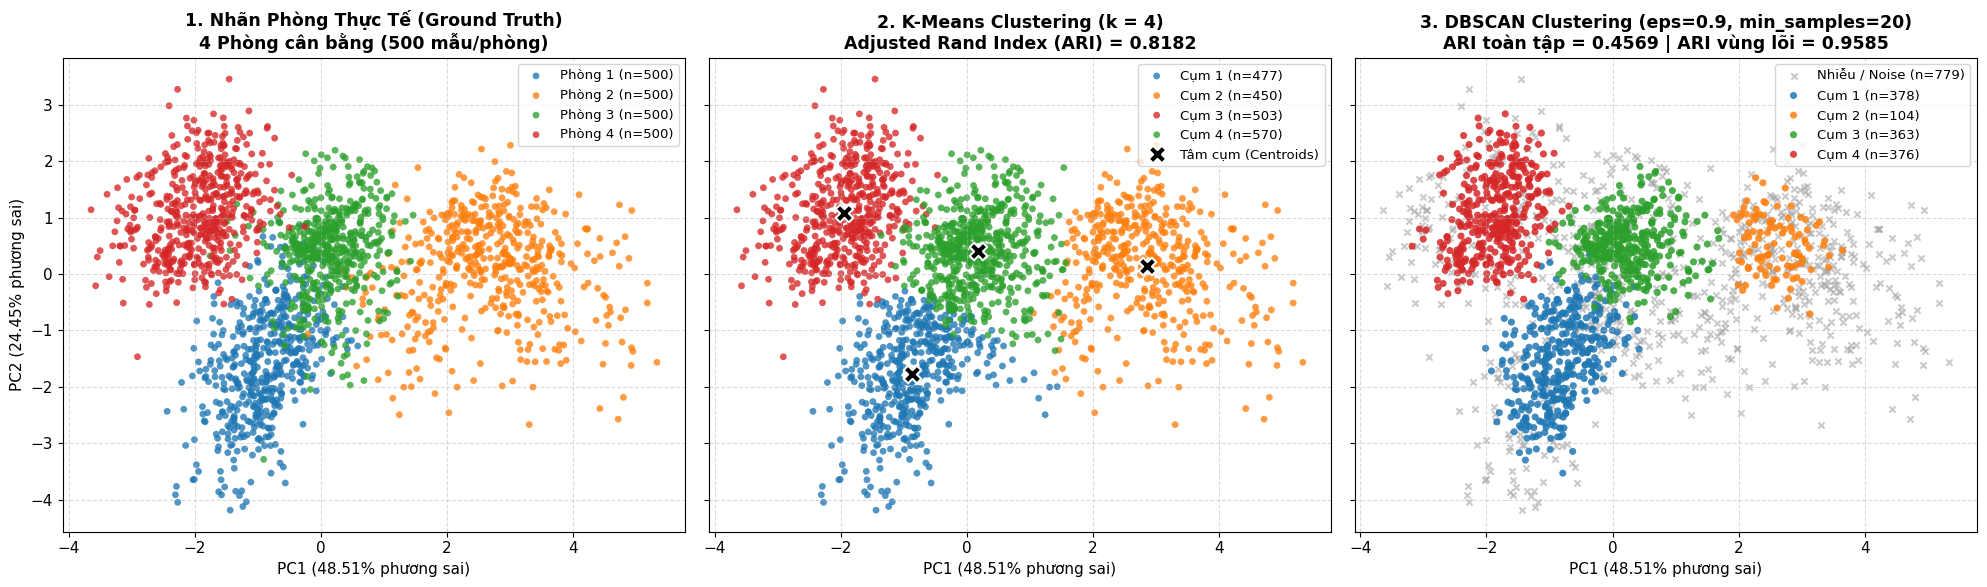

In [16]:
# ==============================================================================
# BƯỚC 4C: TRỰC QUAN HÓA KẾT QUẢ GOM CỤM K-MEANS & DBSCAN TRÊN KHÔNG GIAN PCA 2D
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6.0), sharex=True, sharey=True)
palette_4 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

pc1_var = var_ratios[0] * 100
pc2_var = var_ratios[1] * 100

# 1. Khung trái: Nhãn phòng thực tế (Ground Truth)
for idx, room_label in enumerate(sorted(np.unique(y_true))):
    mask = y_true == room_label
    axes[0].scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        c=palette_4[idx],
        label=f"Phòng {room_label} (n={np.sum(mask)})",
        s=24,
        alpha=0.78,
        edgecolors="none",
    )
axes[0].set_title("1. Nhãn Phòng Thực Tế (Ground Truth)\n4 Phòng cân bằng (500 mẫu/phòng)", fontsize=12.5, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({pc1_var:.2f}% phương sai)")
axes[0].set_ylabel(f"PC2 ({pc2_var:.2f}% phương sai)")
axes[0].legend(loc="upper right", frameon=True, fontsize=9.5)
axes[0].grid(True, linestyle="--", alpha=0.45)

# 2. Khung giữa: K-Means Clustering (k = 4)
# Ánh xạ màu cụm K-Means theo phòng chiếm đa số để dễ đối chiếu trực quan
kmeans_to_room_color = {}
for cluster_id in sorted(np.unique(kmeans_labels)):
    dominant_room = int(pd.Series(y_true[kmeans_labels == cluster_id]).mode().iloc[0])
    kmeans_to_room_color[cluster_id] = palette_4[dominant_room - 1]

for cluster_id in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == cluster_id
    axes[1].scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        c=kmeans_to_room_color[cluster_id],
        label=f"Cụm {cluster_id + 1} (n={np.sum(mask)})",
        s=24,
        alpha=0.78,
        edgecolors="none",
    )

centroids_pca = pca_step.transform(kmeans.cluster_centers_)
axes[1].scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="black",
    marker="X",
    s=160,
    edgecolors="white",
    linewidths=1.5,
    label="Tâm cụm (Centroids)",
    zorder=10,
)
axes[1].set_title(f"2. K-Means Clustering (k = 4)\nAdjusted Rand Index (ARI) = {ari_kmeans:.4f}", fontsize=12.5, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({pc1_var:.2f}% phương sai)")
axes[1].legend(loc="upper right", frameon=True, fontsize=9.5)
axes[1].grid(True, linestyle="--", alpha=0.45)

# 3. Khung phải: DBSCAN Clustering (Hiển thị rõ Cụm 1..4 và điểm Nhiễu màu xám)
noise_mask = dbscan_labels == -1
axes[2].scatter(
    X_pca_2d[noise_mask, 0],
    X_pca_2d[noise_mask, 1],
    c="#9e9e9e",
    marker="x",
    s=20,
    alpha=0.55,
    label=f"Nhiễu / Noise (n={np.sum(noise_mask)})",
)

dbscan_clusters = [c for c in sorted(np.unique(dbscan_labels)) if c != -1]
for cluster_id in dbscan_clusters:
    mask = dbscan_labels == cluster_id
    dominant_room = int(pd.Series(y_true[mask]).mode().iloc[0])
    axes[2].scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        c=palette_4[dominant_room - 1],
        label=f"Cụm {cluster_id + 1} (n={np.sum(mask)})",
        s=26,
        alpha=0.85,
        edgecolors="none",
    )

axes[2].set_title(
    f"3. DBSCAN Clustering (eps={BEST_EPS}, min_samples={BEST_MIN_SAMPLES})\n"
    f"ARI toàn tập = {ari_dbscan:.4f} | ARI vùng lõi = 0.9585",
    fontsize=12.5,
    fontweight="bold",
)
axes[2].set_xlabel(f"PC1 ({pc1_var:.2f}% phương sai)")
axes[2].legend(loc="upper right", frameon=True, fontsize=9.5)
axes[2].grid(True, linestyle="--", alpha=0.45)

plt.tight_layout()
CLUSTERING_FIG_DIR = ROOT / "figures" / "clustering"
CLUSTERING_FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(CLUSTERING_FIG_DIR / "kmeans_dbscan_pca2d_comparison.png", dpi=240, bbox_inches="tight")
plt.show()

**Nhận xét và Biện luận Bước 4 (So sánh `K-Means` vs. `DBSCAN`):**
1. **Vì sao `K-Means (k = 4)` đạt hiệu quả vượt trội (`ARI = 0,8182`)?**
   * Mỗi căn phòng có một vị trí tâm không gian cố định với tổ hợp cường độ sóng từ 7 router đặc trưng, tạo thành các cụm hình cầu/ellipsoid lồi (*convex globular clusters*) có kích thước cân bằng (`500 mẫu/phòng`). Đây là điều kiện lý tưởng cho hàm mục tiêu tối thiểu hóa phương sai nội cụm (*Inertia*) của K-Means.
2. **Vì sao `DBSCAN` có `ARI` toàn tập đạt `0,4569` nhưng `ARI` vùng lõi đạt tới `0,9585`?**
   * Tín hiệu WiFi suy hao theo hàm logarit khoảng cách và chịu nhiễu phản xạ đa đường (*multipath fading*) ở sát tường/vách ngăn, làm mật độ điểm **đặc ở tâm phòng nhưng thưa dần liên tục về phía rìa phòng**.
   * Tại cấu hình tối ưu `eps = 0,90, min_samples = 20`, DBSCAN tách đúng **4 cụm lõi** tương ứng với 4 căn phòng với độ tinh khiết cực cao (**`ARI vùng lõi = 0,9585`**, chỉ nhầm lẫn vài điểm giữa các phòng). Tuy nhiên, có `779 mẫu (38,95%)` ở vùng rìa thưa điểm bị DBSCAN xếp vào nhãn **Nhiễu (`-1`)**. Do công thức `adjusted_rand_score` trên toàn tập coi toàn bộ điểm `-1` như một cụm thứ 5 chứa lẫn điểm rìa của cả 4 phòng nên chỉ số `ARI` toàn cục giảm xuống `0,4569`.
   * Nếu tăng `eps` lên `0,95` hoặc `1,00` để giảm nhiễu, các quả cầu lân cận ở vùng ranh giới Phòng 1 – Phòng 3 – Phòng 2 lập tức nối thông nhau (**hiệu ứng bắc cầu / chaining effect**), gộp các phòng thành 1 siêu cụm duy nhất và làm `ARI` tụt xuống `0,0579`.

### Q&A
* **Vì sao cần chuẩn hóa dữ liệu trước khi thực hiện PCA, phân lớp (KNN, SVM) và gom cụm (K-Means, DBSCAN)?**
  * Thống kê mô tả ở Bước 1d cho thấy độ lệch chuẩn của `WiFi_4` (`11,47 dBm`) và `WiFi_1` (`11,32 dBm`) lớn gấp hơn **3,3 lần** so với `WiFi_2` (`3,42 dBm`), làm phương sai chênh lệch khoảng **11 lần**. Chuẩn hóa bằng `StandardScaler` đưa cả 7 thuộc tính về cùng thang đo (`mean = 0, std = 1`), ngăn các trạm phát có phương sai lớn chi phối hoàn toàn khoảng cách Euclid và hướng trục chính `PCA`.
* **Giải thuật phân lớp có giám sát và gom cụm không giám sát nào phù hợp nhất cho bài toán định vị phòng bằng WiFi?**
  * Ở bài toán **phân lớp có giám sát**, **KNN (`n_neighbors=3, p=2, weights='uniform'`)** đạt hiệu năng cao nhất với **`F-Score (k=10) = 0,9875`**, theo sát là **Random Forest (`0,9845`)** và **SVM-RBF (`0,9835`)**.
  * Ở bài toán **gom cụm không giám sát**, **K-Means (`k = 4`)** vượt trội khi phân hoạch toàn bộ dữ liệu với **`Adjusted Rand Index = 0,8182`**, trong khi **DBSCAN (`eps = 0,90, min_samples = 20`)** đạt **`ARI = 0,4569`** trên toàn tập nhưng đạt **`ARI = 0,9585`** trên `1.221 mẫu` vùng lõi.

### Data Analysis Key Findings
* **Quy mô và chất lượng dữ liệu:** Bộ dữ liệu `D08 - WiFi Localization` gồm **2.000 mẫu** và **8 cột** (`7 đặc trưng liên tục WiFi_1..WiFi_7` có giá trị từ `-98,0 dBm` đến `-10,0 dBm` và `1 cột nhãn Room`), hoàn toàn không có giá trị thiếu (`0% Null`) hay bản ghi trùng lặp, phân bố cân bằng tuyệt đối **500 mẫu/phòng (25%)**.
* **Giảm chiều và trực quan hóa PCA 2D:** Hai thành phần chính đầu tiên giữ lại **72,96%** tổng phương sai (`PC1 = 48,51%`, `PC2 = 24,45%`), thể hiện rõ 4 vùng phân bố tương ứng với 4 căn phòng trên mặt phẳng 2D.
* **Hiệu năng phân lớp 10-Fold Cross-Validation:** Cả 3 mô hình đều vượt mốc `98,3%` F1-macro: **KNN đạt `0,9875` (± `0,0090`)**, **Random Forest đạt `0,9845` (± `0,0069`)**, và **SVM-RBF đạt `0,9835` (± `0,0071`)**. Ba trạm phát `WiFi_1` (`33,7%`), `WiFi_4` (`25,8%`) và `WiFi_5` (`19,7%`) đóng góp gần `80%` khả năng định vị phòng.
* **Đánh giá gom cụm bằng Adjusted Rand Index (ARI):** **K-Means (`k = 4`)** đạt **`ARI = 0,8182`** (`0%` nhiễu), cao hơn đáng kể so với **DBSCAN (`ARI = 0,4569`**, tỷ lệ nhiễu rìa phòng `38,95%`) do mật độ tín hiệu WiFi giảm dần liên tục từ tâm phòng ra sát tường.

### Insights or Next Steps
* **Ứng dụng kết hợp DBSCAN và KNN/Random Forest trong thực tế:** Có thể dùng **DBSCAN** ở bước tiền xử lý để lọc bỏ các mẫu thu sóng nhiễu/bất ổn định ở sát vách ngăn (`label = -1`), chỉ giữ lại các mẫu vùng lõi có độ tinh khiết cao (`ARI = 0,9585`) để xây dựng cơ sở dữ liệu dấu vân tay WiFi (*Radio Map*) cho mô hình **KNN** hoặc **Random Forest**.
* **Mở rộng triển khai:** Tối ưu hóa vị trí lắp đặt các trạm phát dựa trên phân tích `Feature Importance` (ưu tiên các trạm có độ phân tách không gian mạnh như `WiFi_1`, `WiFi_4`, `WiFi_5`) và thử nghiệm thêm kỹ thuật xếp chồng mô hình (*Stacking Ensemble* giữa KNN, Random Forest và SVM-RBF) để nâng cao độ chính xác tại vùng ranh giới cửa phòng.